In [59]:
import xarray as xr
import pygrib
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd

In [19]:
def calc_D20(temp, depth):
    """
    temp: (nz, ny, nx)
    depth: (nz,)
    """
    mask = (temp[:-1] - 20) * (temp[1:] - 20) <= 0
    valid = mask.any(axis=0)

    k = np.argmax(mask, axis=0)

    ny, nx = temp.shape[1:]
    D20 = np.full((ny, nx), np.nan)

    j, i = np.where(valid)
    kk = k[j, i]

    T1 = temp[kk, j, i]
    T2 = temp[kk + 1, j, i]

    good = np.abs(T2 - T1) > 1e-6

    j = j[good]
    i = i[good]
    kk = kk[good]

    T1 = temp[kk, j, i]
    T2 = temp[kk + 1, j, i]

    z1 = depth[kk]
    z2 = depth[kk + 1]

    D20[j, i] = z1 + (20 - T1) * (z2 - z1) / (T2 - T1)

    return D20

def get_h_month(grb_file, month, ds_clim):

    grbs = pygrib.open(grb_file)

    temp_list = []
    depth_list = []

    for g in grbs:
        if "Potential temperature" in g.name or "POT" in g.name:
            temp_list.append(g.values)
            depth_list.append(g.level)

    temp = np.array(temp_list)
    depth = np.array(depth_list)

    temp[temp > 1000] = np.nan
    temp = temp - 273.15

    lats, lons = g.latlons()

    D20_obs = calc_D20(temp, depth)
    temp_clim = ds_clim["pottmp"].isel(time=month - 1).values
    temp_clim = temp_clim - 273.15

    depth_clim = ds_clim["level"].values
    D20_clim = calc_D20(temp_clim, depth_clim)

    D20_anom = D20_obs - D20_clim

    lat = lats[:, 0]
    lon = lons[0, :]

    lat_mask = (lat >= -5) & (lat <= 5)
    lon_mask = (lon >= 120) & (lon <= 280)

    return np.nanmean(D20_anom[np.ix_(lat_mask, lon_mask)])

In [54]:
pt_mean_file = r"E:\data\pottmp.mon.ltm.1991-2020.nc"
pt_ds = xr.open_dataset(pt_mean_file)

get_h_month("E:\data\godas.M.200008.grb", 8, pt_ds)

c:\Users\xueya\miniconda3\envs\deep_learning\lib\site-packages\xarray\coding\times.py:699: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
c:\Users\xueya\miniconda3\envs\deep_learning\lib\site-packages\xarray\core\indexing.py:524: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  return np.asarray(array[self.key], dtype=None)


-0.2797896313713775

In [55]:
def get_sst_month(grb_file, month, ds_clim):

    grbs = pygrib.open(grb_file)

    sst_list = []

    for g in grbs:
        if "Potential temperature" in g.name or "POT" in g.name:
            sst_list.append(g.values)

    sst = np.array(sst_list)
    sst = np.where(sst > 1000, np.nan, sst)
    sst = sst - 273.15

    grbs.rewind()
    g0 = next(grbs)
    lats, lons = g0.latlons()

    sst_obs = sst[0]

    sst_clim = ds_clim["pottmp"].isel(time=month - 1, level=0).values

    sst_clim = sst_clim - 273.15

    ssta = sst_obs - sst_clim

    lat = lats[:, 0]
    lon = lons[0, :]

    # Niño3
    lat_mask = (lat >= -5) & (lat <= 5)
    lon_mask = (lon >= 210) & (lon <= 270)

    return np.nanmean(ssta[np.ix_(lat_mask, lon_mask)])

In [56]:
get_sst_month("E:\data\godas.M.198010.grb", 10, pt_ds)

-0.3734944321017498

In [57]:
h_series = []
sst_series = []
time_index = []

for year in range(1980, 2026):
    for month in range(1, 13):

        file_name = f"E:/data/godas.M.{year}{month:02d}.grb"
        time_index.append(f"{year}-{month:02d}")

        if not os.path.exists(file_name):
            print(f"[MISSING FILE] {file_name}")
            h_series.append(np.nan)
            sst_series.append(np.nan)
            continue

        try:
            h = get_h_month(file_name, month, pt_ds)
            sst = get_sst_month(file_name, month, pt_ds)
            h_series.append(h)
            sst_series.append(sst)

        except Exception as e:
            print(f"[ERROR] {file_name}: {e}")
            h_series.append(np.nan)
            sst_series.append(np.nan)

h_series = np.array(h_series)
sst_series = np.array(sst_series)

In [61]:
df = pd.DataFrame({
    "time": time_index,
    "h": h_series,
    "sst": sst_series
})

df.to_csv("ENSO_h_sst_series.csv", index=False)

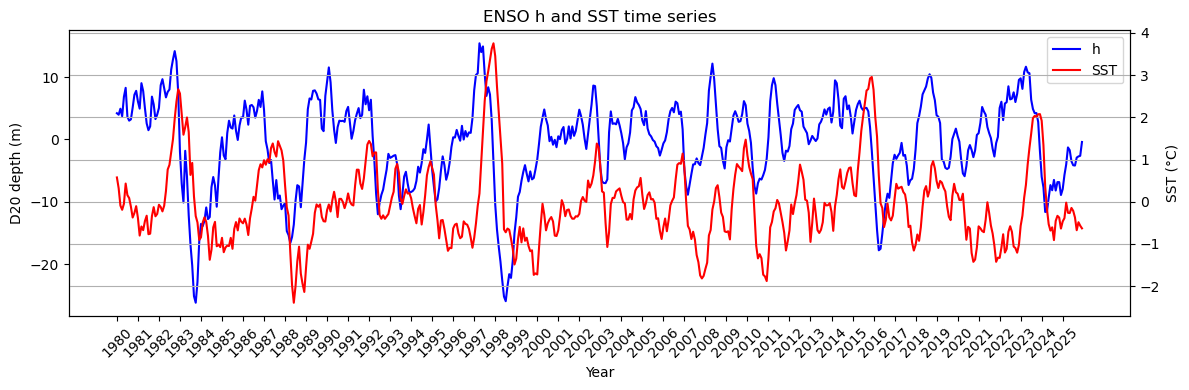

In [58]:
year_ticks = np.arange(0, len(h_series), 12)
year_labels = [time_index[i][:4] for i in year_ticks]

fig, ax1 = plt.subplots(figsize=(12, 4))

line1 = ax1.plot(h_series, label='h', color='b')
ax1.set_ylabel('D20 depth (m)')

ax2 = ax1.twinx()
line2 = ax2.plot(sst_series, label='SST', color='r')
ax2.set_ylabel('SST (°C)')

ax1.set_xticks(year_ticks)
ax1.set_xticklabels(year_labels, rotation=45)
ax1.set_xlabel('Year')

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.title('ENSO h and SST time series')
plt.tight_layout()
plt.grid()
plt.show()